# What changes when the representation is probabilistic?

We return to **Asteron's 80 × 90 RNA table**, the same observations used for PCA. This time we fit a **six-factor Gaussian MOFA-FLEX model**. We will ask how assumptions about residuals and weights enter the model, then distinguish changing those assumptions from changing how the model is optimised.

Our route is to fit a dense baseline, inspect its representation and reconstruction, change the learning rate, compare a sparsity-inducing weight prior, and check sensitivity to initialisation. Protein and Borealis remain outside every fit in this notebook.

**Predict:** will a likelihood or a prior make the axes uniquely biological? Is the learning rate an assumption about disease?

### Start from the saved observations

The local `course_utils` import supplies the data readers, plotting and comparison helpers, `FIT`, and names such as `np`, `pd` and `plt`. `load_experiment()` reads all four canonical AnnData tables; we will select only Asteron RNA. It neither generates new observations nor loads true scores or weights.

In [2]:
from pathlib import Path
import sys, time
HERE = Path.cwd() if Path('course_utils.py').exists() else Path.cwd() / 'notebooks'
sys.path.insert(0, str(HERE))
from course_utils import *
from IPython.display import display
from sklearn.decomposition import PCA
# Observations only. Ground truth is loaded explicitly for later diagnostics.
data = load_experiment()

### Make the fitting settings visible

We import MOFA-FLEX explicitly because the model construction and fit calls remain in this notebook. PyTorch is restricted to one CPU thread for these small fits. `FIT` is an ordinary settings dictionary from `course_utils`; printing it lets us see the Gaussian likelihood, seed, learning rate, epoch cap and stopping settings that `**FIT` will pass into each fit. Importing and printing these settings does not fit a model.

In [3]:
import mofaflex as mf
import torch
torch.set_num_threads(1)
print('MOFA-FLEX', mf.__version__)
print('Training settings:', FIT)

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.

MOFA-FLEX 0.2.0rc2.dev16+g2710274b7
Training settings: {'device': 'cpu', 'likelihoods': 'Normal', 'seed': 42, 'save_path': False, 'max_epochs': 1200, 'lr': 0.02, 'early_stopper_patience': 250, 'batch_size': 0, 'subset_var': None, 'plot_data_overview': False, 'update_every': -1, 'scale_elbo': True}


/Users/flores/Dropbox/EBI/Teaching/VIB/MOFA_training/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
/Users/flores/Dropbox/EBI/Teaching/VIB/MOFA_training/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.


## Describe the same RNA table with a probability model

No new measurements or labels enter fitting. `rna` selects Asteron RNA, and `standardized(rna)` creates the centred, single-RMS-scaled array `x` used for our reconstruction checks. We supply **raw AnnData** to MOFA-FLEX; its Gaussian likelihood carries out the corresponding preprocessing internally. We do not pass `x` back into the model and scale it twice.

The model describes each centred/scaled measurement as a noisy score–weight product:

$$\widetilde Y_{nd}\mid Z,W,\sigma_d\sim\mathcal N((ZW)_{nd},\sigma_d^2),\qquad Z_{nk}\sim\mathcal N(0,1).$$

The dense baseline also places Normal priors on the weights. The likelihood describes residual variation; priors describe assumptions on the latent quantities; the posterior describes those quantities conditional on observations and assumptions. MOFA-FLEX uses variational inference to approximate that posterior. We will mainly inspect its means, so the displayed coordinates do not show all posterior uncertainty.

`schematic('single')` draws the 80 × 90, 80 × 6 and 6 × 90 matrix dimensions. `probabilistic_schematic()` adds a conceptual diagram of priors, likelihood, approximate posterior and numerical inference. Both helpers draw teaching diagrams; neither constructs or fits the model. Unlike classical probabilistic PCA's isotropic residual noise, this Gaussian factor model permits feature-specific residual scales.

(80, 90)


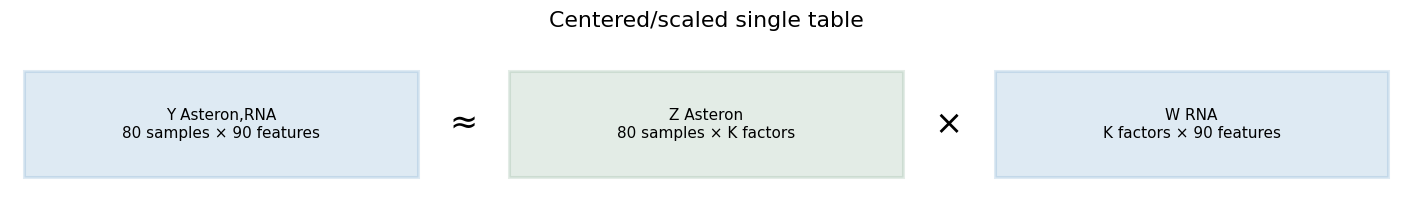

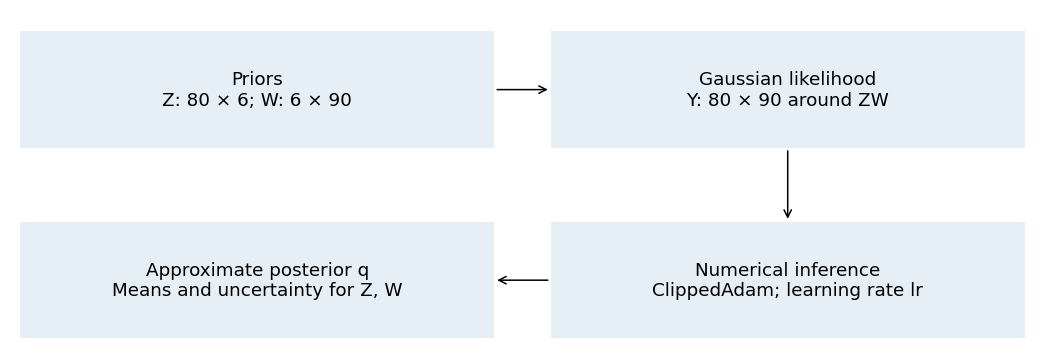

In [4]:
rna = data['Asteron']['RNA']
x = standardized(rna)
print(rna.shape)
schematic('single')
probabilistic_schematic()

## Fit the dense baseline to Asteron RNA

We now fit **six Gaussian factors to Asteron RNA only**, with Normal factor and weight priors and random initialisation. Six is our teaching choice based on the known simulation, not an estimated optimum. A process invisible in RNA can leave a factor describing noise or a mixture instead.

`mf.terms.MofaFlex(...)` constructs the model. The actual inference starts at `.fit(...)`. `make_mudata({'RNA': rna})` checks sample identifiers, orders the rows, copies the one RNA view into a MuData container and carries its sample annotations into `.obs`. It does not add proteins, standardise measurements or fit anything. We use the same container convention later for multiple views.

`**FIT` passes the previously printed settings as keyword arguments. This baseline uses seed 42, full-batch CPU training, base learning rate .02, at most 1,200 epochs and early-stopping patience 250. ClippedAdam optimises the stochastic variational objective; the base rate and stopping rule concern numerical fitting, not biological assumptions.

After fitting, `get_factors()` returns a dictionary of sample-factor tables. There is only one sample group here, so `next(iter(...values()))` takes its whole **80 × 6 table**, not its first factor. `.loc[rna.obs_names]` fixes inhabitant order. `get_weights()['RNA']` returns a **90 × 6 feature-weight table**, transposed relative to the mathematical W. `export_fit` writes score/weight CSVs, total-R² CSV and a training-loss array under `results/dense_baseline/`; it does not run another fit.

**Predict:** where might reconstruction resemble PCA even if the reported factor axes differ?

In [5]:
baseline = mf.terms.MofaFlex(n_factors=6, factor_prior='Normal',
                             weight_prior='Normal', init_factors='random')
t0 = time.perf_counter()
baseline.fit(make_mudata({'RNA': rna}), **FIT)
print('Fit seconds:', round(time.perf_counter()-t0, 2))

z = next(iter(baseline.get_factors().values())).loc[rna.obs_names]
w = baseline.get_weights()['RNA']  # API: features × factors; equation: W = w.T
export_fit(baseline, 'dense_baseline')

INFO	Initializing factors using 'random' method...


INFO 	 Guessed max_plate_nesting = 2


Fit seconds: 3.88


### Read the representation learned by the dense RNA model

These are diagnostics of the **fitted Normal-weight Asteron RNA model**. `score_plot` draws its first two score columns with disease labels added afterwards. `weights_plot` selects the 18 strongest features across the supplied factor columns and displays their signed weights; the selected heatmap is not the complete 90-feature matrix.

`diagnostics(baseline)` plots `training_loss`, the stochastic negative ELBO, and reports finite values and the last-100-epoch mean. Look for late trends and fluctuations; this helper does not certify convergence. `r2_plot(baseline)` plots each factor's reconstruction R², then returns the whole-model R² table for `display`. Those single-factor values need not sum because the factors need not be orthogonal.

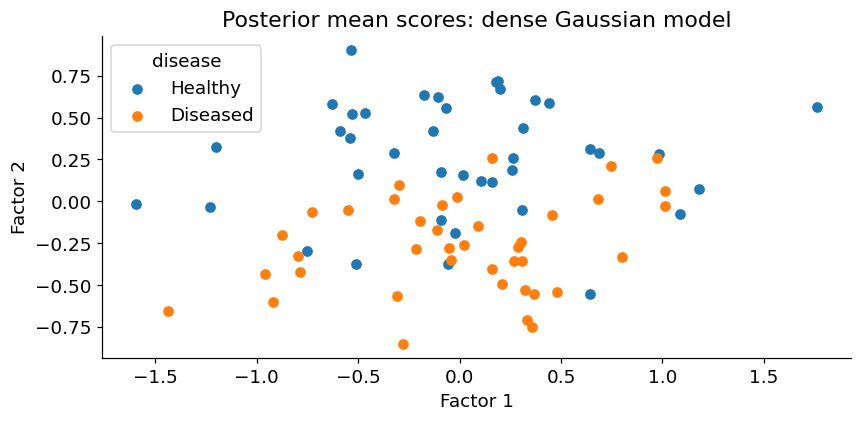

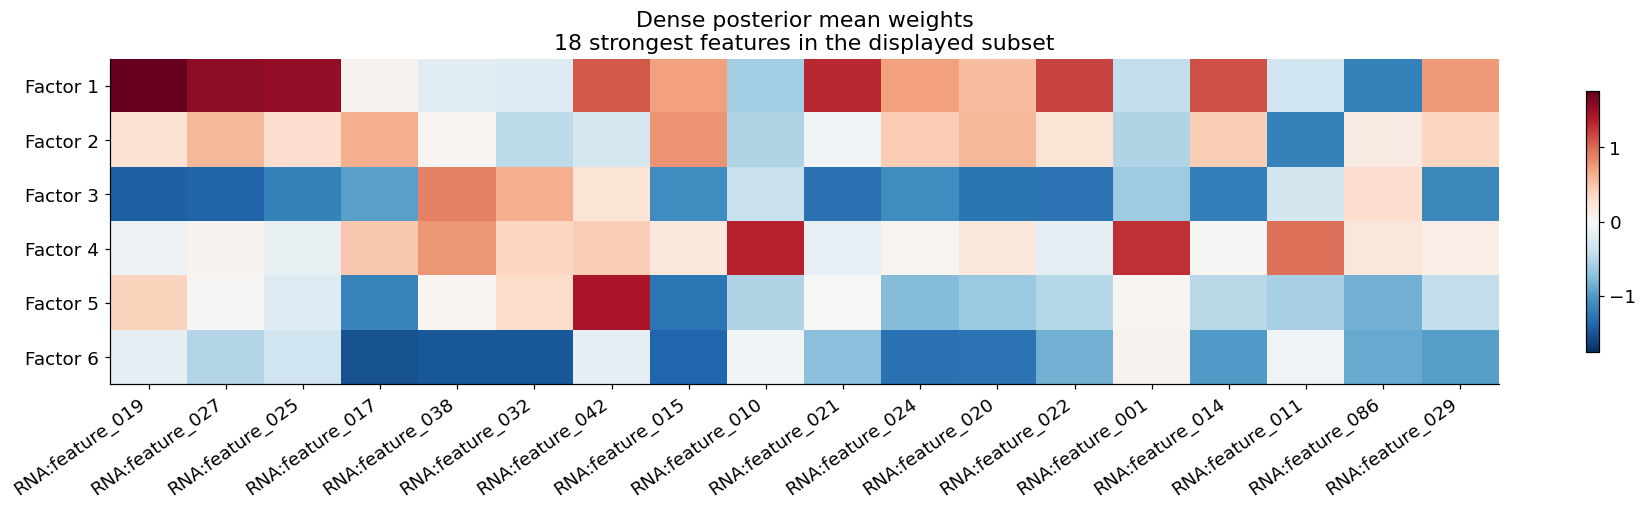

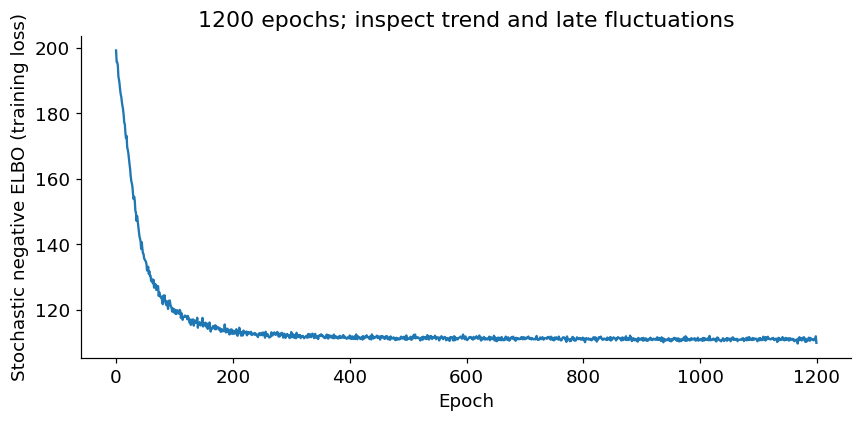

Finite loss: True | last-100 mean: 110.993


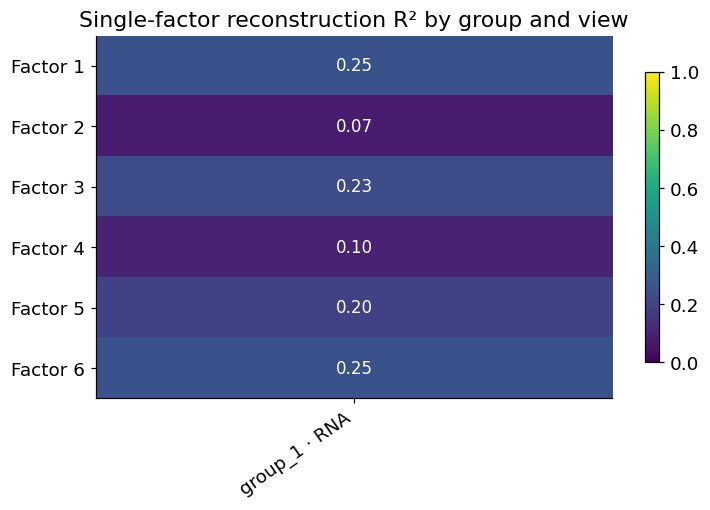

,group,view,R2
0,group_1,RNA,0.886065


In [6]:
score_plot(z, rna.obs, color='disease', title='Posterior mean scores: dense Gaussian model')
weights_plot(w, 'Dense posterior mean weights')
diagnostics(baseline)
display(r2_plot(baseline))

### View the same model's variance summary through MOFA-FLEX

`mf.pl.variance_explained(baseline)` is the package's plotting interface for the **same dense, one-view RNA fit**. It neither retrains the model nor uses the simulation truth. Connect its factor/view summaries with the reconstruction R² we introduced in PCA; keep them separate from correlations with disease.

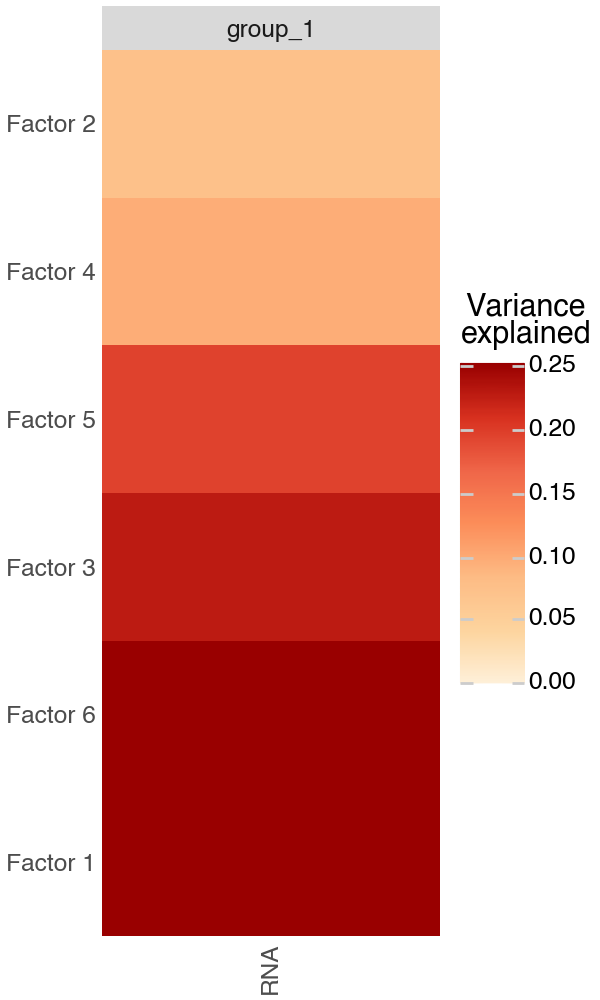

In [7]:
mf.pl.variance_explained(baseline)

### Turn posterior means into an RNA prediction

For the **dense Asteron RNA fit**, `z @ w.T` multiplies an 80 × 6 score table by a 6 × 90 weight table. We compare this 80 × 90 prediction with `x`, the matched centred/scaled observations. `reconstruction_plot` only displays observations, the supplied prediction and their residuals with a common colour scale. The printed mean squared error is calculated directly from those residuals. This product of posterior means is a point summary, not a display of posterior predictive uncertainty.

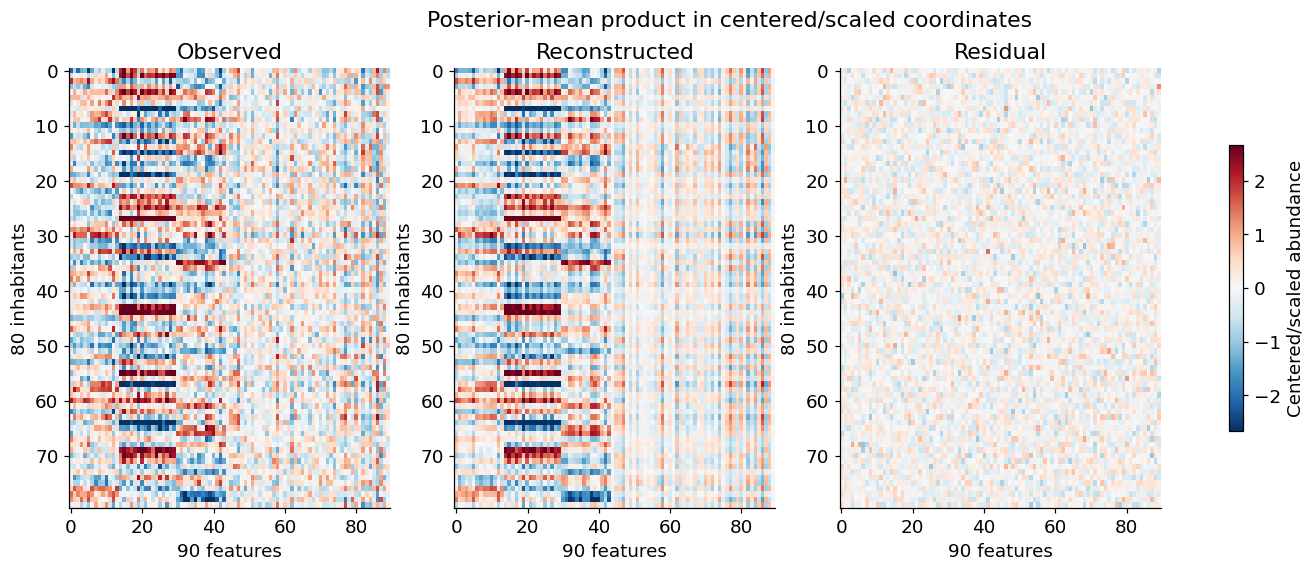

Mean squared reconstruction error: 0.11393451961735004


In [8]:
estimate = z.to_numpy() @ w.to_numpy().T
reconstruction_plot(x, estimate, 'Posterior-mean product in centered/scaled coordinates', figsize=(16, 5.2))
print('Mean squared reconstruction error:', np.mean((x-estimate)**2))

## Change the learning rate while keeping the model fixed

We are still fitting **six-factor, Normal-prior Gaussian models to the same Asteron RNA table**. We reuse the .02 baseline and fit two new models at .005 and .05. Data, priors, seed, random initialisation method, factor count and stopping settings stay the same. The dictionary expression `{**FIT, 'lr': lr}` overrides just the rate for that call without changing `FIT`.

Learning rate controls the size of numerical updates. It is not a sparsity assumption or a prior on disease effects. Equal seeds control the starting random streams, but update trajectories and stopping times can diverge.

**Before running:** which rate might still be improving at the epoch cap? Could two rates reconstruct similarly yet yield different sample representations?

In [9]:
rates = {0.02: baseline}
for lr in [0.005, 0.05]:
    candidate = mf.terms.MofaFlex(n_factors=6, factor_prior='Normal',
                                 weight_prior='Normal', init_factors='random')
    candidate.fit(make_mudata({'RNA': rna}), **{**FIT, 'lr': lr})
    rates[lr] = candidate

INFO	Initializing factors using 'random' method...


INFO 	 Guessed max_plate_nesting = 2


INFO	Initializing factors using 'random' method...


INFO 	 Guessed max_plate_nesting = 2


### Compare numerical progress and reconstructed RNA

No new fits occur here: we inspect the **three dense Asteron RNA models** just fitted. `model.training_loss` supplies each loss curve. The summary reports epochs, late loss change and reconstruction error. Loss is stochastic negative ELBO, so lower trends are informative within this controlled comparison, while individual fluctuations are expected.

`subspace_similarity(z, zz)` matches inhabitant rows, centres the two score tables and compares their column spaces. Near 1 means their spaces are similar even if factor signs or orientations differ. This is a representation comparison with the .02 baseline, not a truth-recovery score.

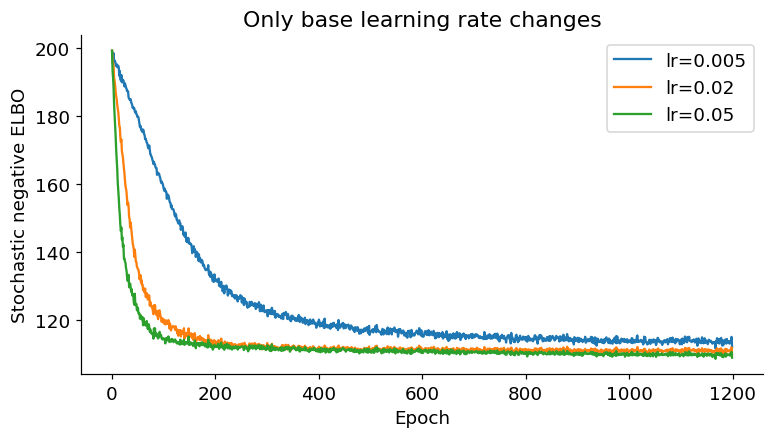

,lr,epochs,last100_loss,loss_change100,mse,baseline_subspace
0,0.005,1200,113.718582,-0.114410,0.117256,0.839777
1,0.020,1200,110.992878,0.003755,0.113935,1.000000
2,0.050,1200,109.796685,-0.094821,0.114691,0.961093


In [10]:
fig, ax = plt.subplots()
rows = []
for lr, model in sorted(rates.items()):
    loss = np.asarray(model.training_loss)
    ax.plot(loss, label=f'lr={lr}')
    zz = next(iter(model.get_factors().values()))
    ww = model.get_weights()['RNA']
    rows.append(dict(lr=lr, epochs=len(loss), last100_loss=loss[-100:].mean(),
                     loss_change100=loss[-100:].mean()-loss[-200:-100].mean(),
                     mse=np.mean((x-zz.to_numpy() @ ww.to_numpy().T)**2),
                     baseline_subspace=subspace_similarity(z, zz)))
ax.set(xlabel='Epoch', ylabel='Stochastic negative ELBO', title='Only base learning rate changes')
ax.legend(); plt.show(); display(pd.DataFrame(rows))

### Check whether similar losses produced similar sample maps

For each of the **three dense RNA fits**, `score_plot` displays the first two returned factors. These are not guaranteed to be the same biological directions across fits. `crosscorr(z, zz)` matches rows by inhabitant identifier and calculates every baseline-factor versus candidate-factor Pearson correlation; `.abs()` removes sign differences. `heatmap` only displays that table. A bright off-diagonal entry can indicate changed order; a pattern spread across entries may indicate mixing.

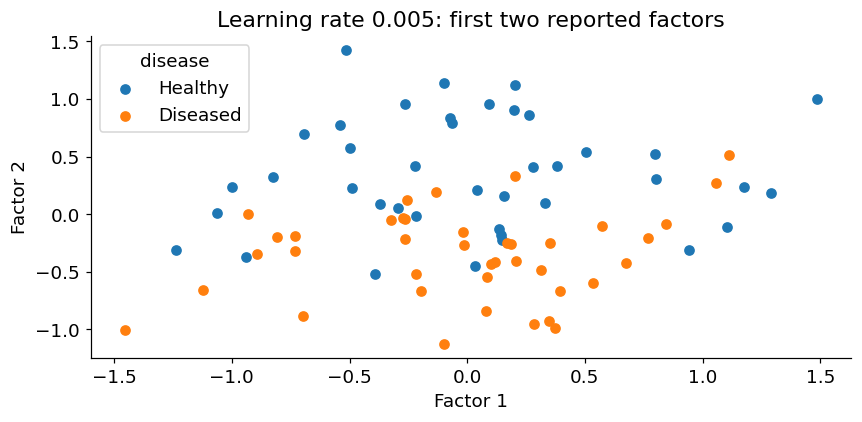

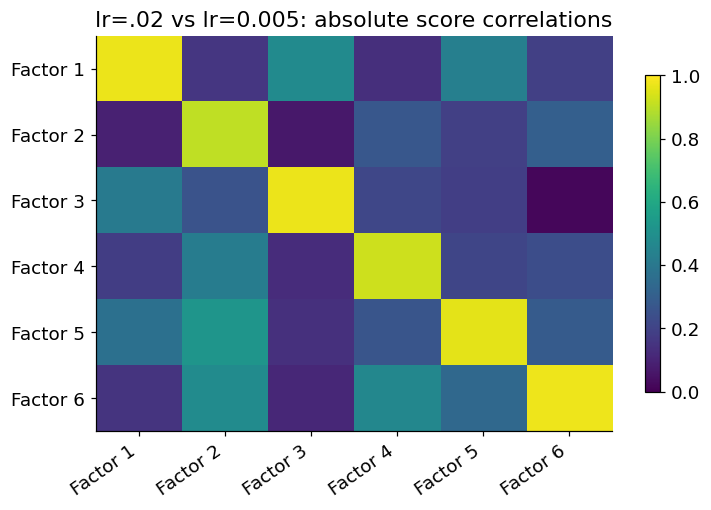

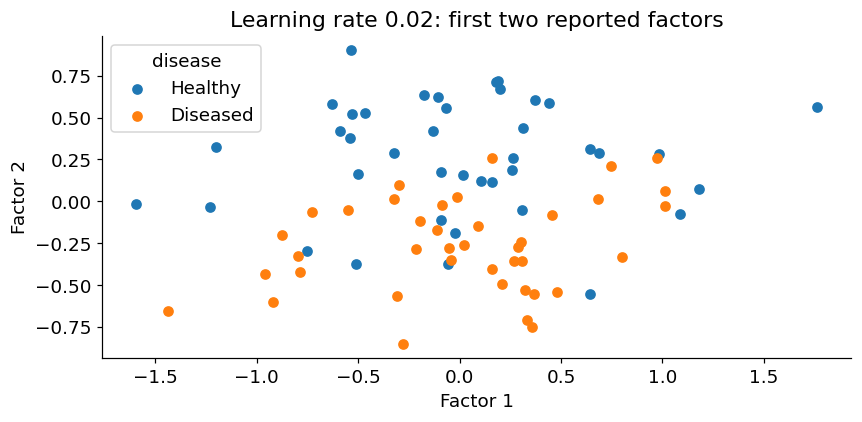

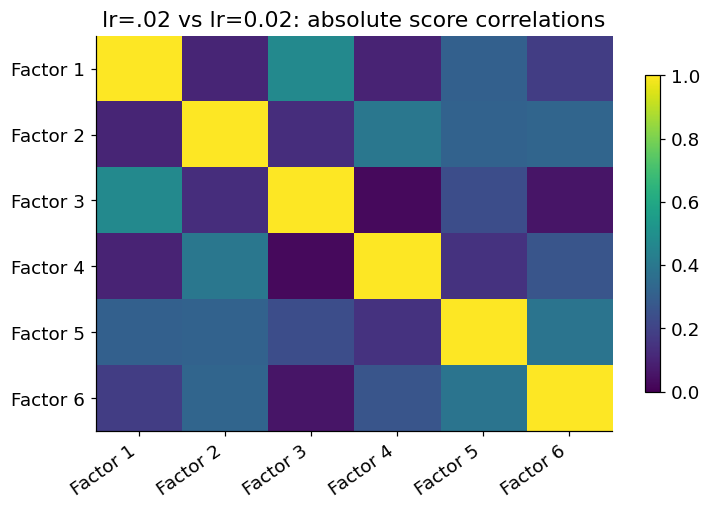

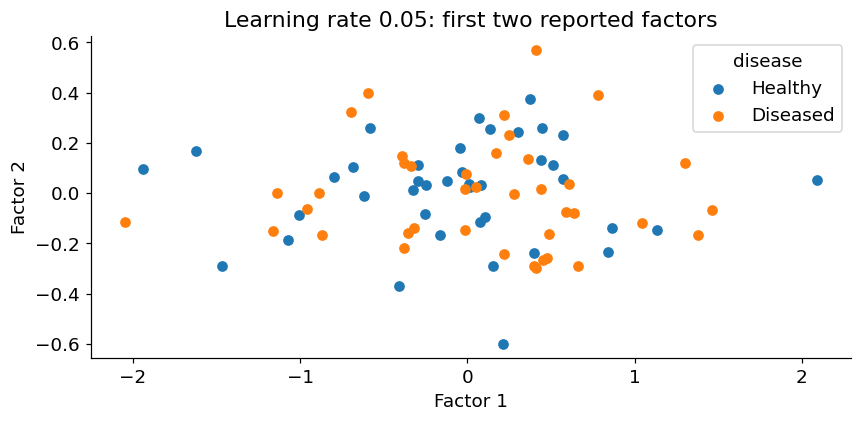

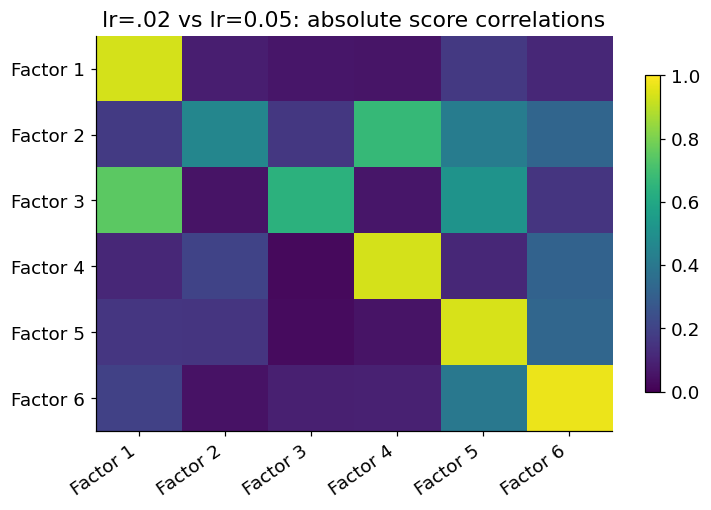

In [11]:
for lr, model in sorted(rates.items()):
    zz = next(iter(model.get_factors().values()))
    score_plot(zz, rna.obs, color='disease', title=f'Learning rate {lr}: first two reported factors')
    heatmap(crosscorr(z, zz).abs(), f'lr=.02 vs lr={lr}: absolute score correlations', vmin=0, vmax=1)

## Change the weight prior on the same RNA data

Pause over the rate-comparison plots before continuing: which curves are still moving late in training, and do similar reconstruction errors coincide with similar score spaces? Reaching the epoch cap is not a convergence certificate.

We now fit **another six-factor Gaussian model to Asteron RNA**, replacing Normal weights with **SpikeSlab** weights. The Normal factor prior, random initialisation, seed, base learning rate .02 and stopping controls remain as in the baseline. The `sparse` model will have its own posterior mean scores `zs` and RNA weights `ws`.

SpikeSlab encourages some feature contributions to be small through inclusion gates and a continuous slab. The returned default weights are probability-weighted means, so sparsity need not appear as exact zeros. We will declare a threshold to describe small weights rather than interpret every small value as feature absence.

The inference calculations also change: SpikeSlab introduces additional variational parameters, a discrete-gradient estimator and a 10× learning-rate multiplier for inclusion parameters. This compares two prior configurations, rather than changing a single numerical penalty. We use the default returned means; the course avoids threshold-output postprocessing because the inspected implementation and its docstring disagree.

**Predict:** could shrinkage make a pattern easier to interpret while suppressing genuine but weak effects?

In [12]:
sparse = mf.terms.MofaFlex(n_factors=6, factor_prior='Normal',
                           weight_prior='SpikeSlab', init_factors='random')
sparse.fit(make_mudata({'RNA': rna}), **FIT)
zs = next(iter(sparse.get_factors().values())).loc[rna.obs_names]
ws = sparse.get_weights()['RNA']
export_fit(sparse, 'sparse')

INFO	Initializing factors using 'random' method...


INFO 	 Guessed max_plate_nesting = 2


### Quantify small weights without calling them exact zeros

We now compare the **dense and SpikeSlab fits of the same Asteron RNA table**. The histogram uses all posterior mean weights. For each factor, the calculation divides absolute weights by that factor's largest absolute weight, then counts entries below 5% of that maximum. `relative_below_5pct` is this declared effective-sparsity measure; it is not an inferred probability that a feature is absent.

The table pairs that measure with whole-model reconstruction R² and epochs. `weights_plot(ws)` shows only the selected 18 strongest sparse-model features, whereas the histogram includes all weights. `diagnostics(sparse)` shows the sparse fit's own loss history. Compare its trend and reconstruction; do not use absolute losses across different priors as a simple model ranking.

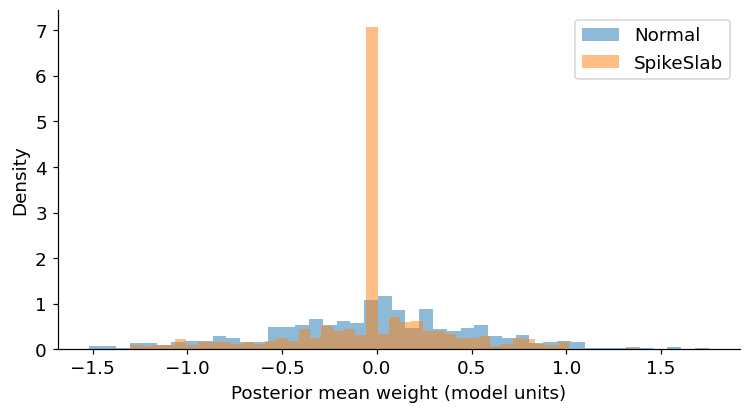

,prior,relative_below_5pct,total_R2,epochs
0,Normal,0.155556,0.886065,1200
1,SpikeSlab,0.437037,0.880657,1200


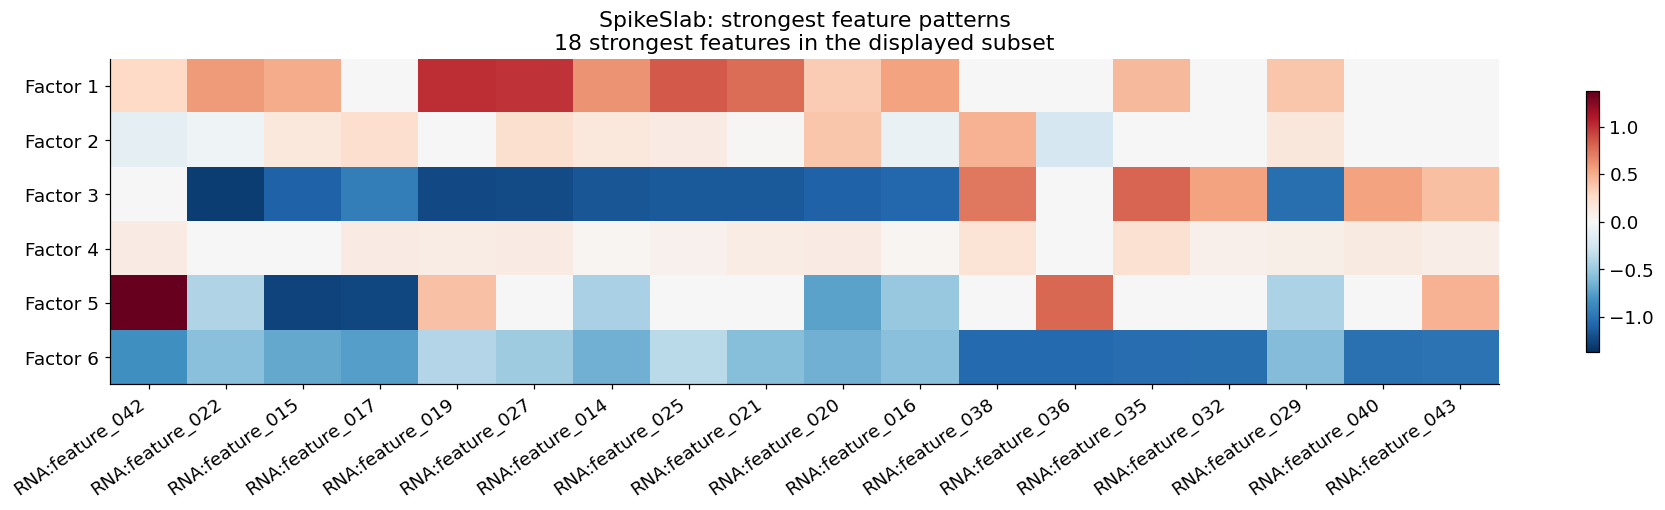

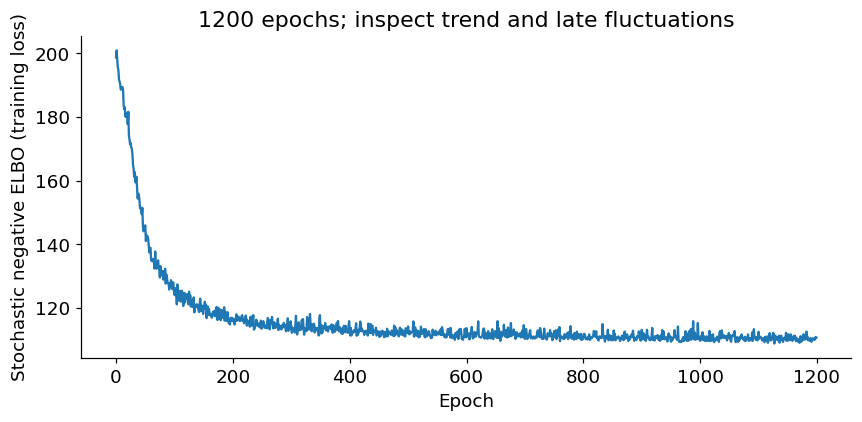

Finite loss: True | last-100 mean: 110.461


In [13]:
fig, ax = plt.subplots()
rows = []
for label, model, ww in [('Normal', baseline, w), ('SpikeSlab', sparse, ws)]:
    values = ww.to_numpy()
    ax.hist(values.ravel(), bins=45, density=True, alpha=.5, label=label)
    relative = np.abs(values) / np.maximum(np.abs(values).max(axis=0), 1e-12)
    rows.append(dict(prior=label, relative_below_5pct=(relative < .05).mean(),
                     total_R2=model.get_r2(type='total').R2.iloc[0],
                     epochs=len(model.training_loss)))
ax.set(xlabel='Posterior mean weight (model units)', ylabel='Density'); ax.legend(); plt.show()
display(pd.DataFrame(rows))
weights_plot(ws, 'SpikeSlab: strongest feature patterns')
diagnostics(sparse)

## Ask whether the representation depends on the starting point

Read the preceding small-weight fractions and reconstruction R² together. Does stronger shrinkage preserve the same reconstruction quality? Sparsity alone does not establish that a weight pattern is biologically correct.

We next fit **two more six-factor models to Asteron RNA**: one with Normal weights and one with SpikeSlab weights, now at seed 43 rather than 42. Each keeps its corresponding prior configuration, random initialisation method, base learning rate .02 and stopping controls. We compare each repeat with its same-prior seed-42 fit, rather than compare unrelated factor indices.

`subspace_similarity` centres matched score rows and compares the spaces spanned by their columns using principal angles. Its returned mean squared cosine is between 0 and 1; a value near 1 indicates closely matching spaces. Sign changes, permutations and rotations within the same space do not reduce it. The correlation heatmap instead compares individual axes, which can look different even when their combined spaces agree.

**Predict:** can two fits reconstruct the same measurements well but distribute variation across different factor columns?

INFO	Initializing factors using 'random' method...


INFO 	 Guessed max_plate_nesting = 2


INFO	Training converged after 937 epochs.


INFO	Initializing factors using 'random' method...


INFO 	 Guessed max_plate_nesting = 2


INFO	Training converged after 1165 epochs.


Normal       0.971158
SpikeSlab    0.749860
Name: Two-seed score-subspace similarity, dtype: float64

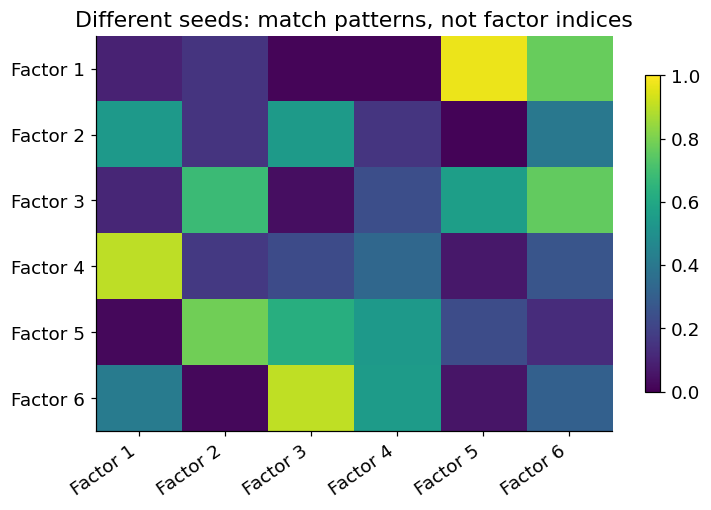

In [14]:
repeat = mf.terms.MofaFlex(n_factors=6, factor_prior='Normal',
                           weight_prior='Normal', init_factors='random')

repeat.fit(make_mudata({'RNA': rna}), **{**FIT, 'seed': 43})
z_repeat = next(iter(repeat.get_factors().values()))
sparse_repeat = mf.terms.MofaFlex(n_factors=6, factor_prior='Normal',
                                  weight_prior='SpikeSlab', init_factors='random')
sparse_repeat.fit(make_mudata({'RNA': rna}), **{**FIT, 'seed': 43})
zs_repeat = next(iter(sparse_repeat.get_factors().values()))
display(pd.Series({'Normal': subspace_similarity(z, z_repeat),
                   'SpikeSlab': subspace_similarity(zs, zs_repeat)}, name='Two-seed score-subspace similarity'))
heatmap(crosscorr(z, z_repeat).abs(), 'Different seeds: match patterns, not factor indices', vmin=0, vmax=1)

### Reveal truth only after the RNA models have been fitted

`load_truth()` now reads the teacher arrays for diagnosis; none entered the preceding MOFA-FLEX fits. We compare the **seed-42 Normal and SpikeSlab RNA representations** with the six known Asteron activities.

`truth_projection(scores, true_scores)` matches inhabitants, centres the tables and uses least squares to predict each true activity from all learned score columns. Its training R² describes how much of that activity lies in the learned score space; it is unchanged by rotations of that space. This small diagnostic regression does not refit MOFA-FLEX or alter its scores. By contrast, `crosscorr` compares individual learned and true axes, and absolute correlations resolve signs but not mixtures. `heatmap` simply displays the resulting tables. Keep both diagnostics distinct from reconstruction of observed RNA.

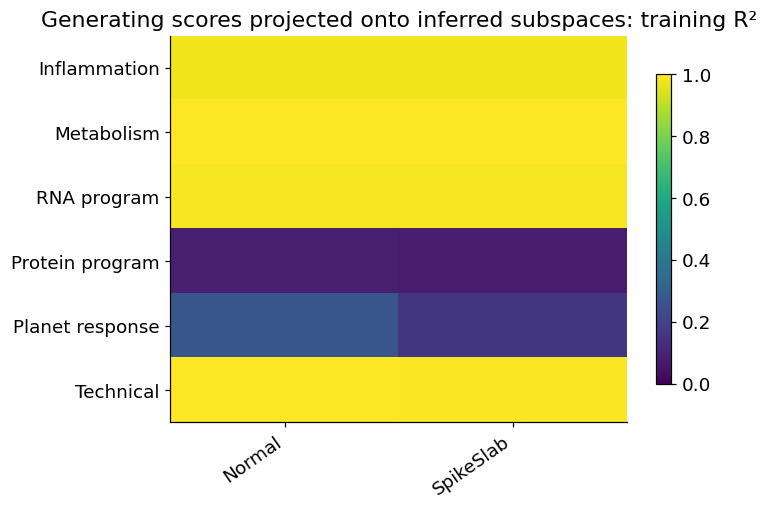

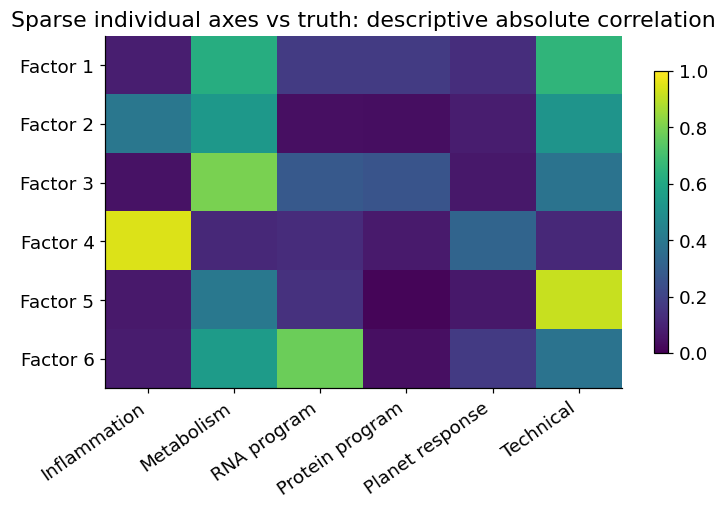

In [15]:
teacher = load_truth()
comparison = pd.DataFrame({label: truth_projection(zz, teacher['scores']['Asteron'])
                           for label, zz in [('Normal', z), ('SpikeSlab', zs)]})


heatmap(comparison, 'Generating scores projected onto inferred subspaces: training R²', vmin=0, vmax=1)
heatmap(crosscorr(zs, teacher['scores']['Asteron']).abs(),
        'Sparse individual axes vs truth: descriptive absolute correlation', vmin=0, vmax=1)

## What did the probability model add?

We have fitted **the same Asteron RNA measurements throughout**, first under Normal weights and then under SpikeSlab weights, and examined optimisation and initialisation choices separately. Return to the plots together: which conclusions concern reconstruction, which concern numerical behaviour, and which depend on the known simulation truth?

The likelihood, priors, approximate posterior and optimiser play different roles. A late training plateau does not establish biological recovery, sparse weights need not be more correct, and two seeds illustrate sensitivity rather than estimate reliability. A learned score space can contain a process without isolating it in one axis.

We now have a way to fit one table and inspect its result. **Next, both institutes will analyse their RNA and protein independently. What will it take to decide whether their separately fitted patterns correspond?**

For optional exploration, vary factor count or repeat both prior configurations at a third seed. Do not choose complexity or a prior solely by training reconstruction.